# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3381 Марков Марк Михайлович. Вариант №12.


## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.


## Основные теоретические положения

### Дискретизация по времени и частота Найквиста
Дискретный сигнал формируется путем взятия отсчетов непрерывного аналогового сигнала $x(t)$ в равноотстоящие моменты времени $t_n = nT$:
$$x(n) \equiv x(nT), \quad n \in \mathbb{Z},$$
где $T = 1/f_{\mathrm{d}}$ — период дискретизации, а $f_{\mathrm{d}}$ — частота дискретизации. В соответствии с теоремой Котельникова, любой непрерывный сигнал, частота которого ограничена сверху значением $f_{max}$, может быть точно и однозначно восстановлен по своим дискретным отсчетам, взятым с частотой $$f_{d} \geq 2f_{max}.$$ Частота Найквиста — частота, определяющая максимальную частоту сигнала, которую можно записать и воспроизвести без искажений $$f_{N} = \frac{f_{d}}{2}.$$ Основная полоса нормированных частот дискретного сигнала охватывает диапазон $\hat{\omega} \in [0, \pi]$ (или $\hat{f} = \hat{\omega}/(2\pi) \in [0, 0.5]$), что в шкале физических частот соответствует интервалу $[0, f_{\mathrm{d}}/2],$ где $\hat{\omega} = \frac{\omega}{f_{d}} = \omega T$ — нормированная циклическая частота.

### Линейные дискретные системы (ЛДС)
Дискретная система называется линейной и стационарной, если для нее выполняется условия аддитивности $$x_1(nT) \rightsquigarrow y_1(nT), \quad x_2(nT) \rightsquigarrow y_2(nT) \Rightarrow x_1(nT)+x_2(nT) \rightsquigarrow y_1(nT)+y_2(nT),$$ однородности $$x(nT) \rightsquigarrow y(nT) \Rightarrow k \cdot x(nT) \rightsquigarrow k \cdot y(nT) \quad \forall k$$ и инвариантности $$x(nT) \rightsquigarrow y(nT) \Rightarrow x((n+s)T) \rightsquigarrow y((n+s)T) \quad \forall s.$$ Динамические свойства ЛДС полностью определяются ее импульсной характеристикой (ИХ) $h(n)$ — реакцией на цифровой единичный импульс:
$$u_0(n) = \begin{cases} 1, & n = 0, \\ 0, & n \ne 0. \end{cases}$$
При нулевых начальных условиях связь между входным сигналом $x(n)$ и реакцией $y(n)$ выражается операцией линейной дискретной свертки:
$$y(n) = x(n) * h(n) = \sum_{m=0}^{\infty} x(m) h(n - m) = \sum_{m=0}^{\infty} h(m) x(n - m).$$

### Разностные уравнения и передаточная функция
Рекурсивные фильтры описываются линейным разностным уравнением порядком $max\{(N-1),(M-1)\}$:
$$y(n) = \sum_{i=0}^{N-1} b_i x(n-i) - \sum_{k=1}^{M-1} a_k y(n-k).$$
Применяя прямое $Z$-преобразование ($X(z) = \mathcal{Z}\{x(nT)\} = \sum_{n=0}^{\infty} x(n) z^{-n}$) при нулевых начальных условиях, получают передаточную функцию системы $H(z)$:
$$H(z) = \frac{Y(z)}{X(z)} = \frac{\sum_{i=0}^{N-1} b_i z^{-i}}{1 + \sum_{k=1}^{M-1} a_k z^{-k}} = \frac{B(z)}{A(z)}.$$

### Аналитическое вычисление импульсной характеристики (обратное Z-преобразование)
Для рекурсивного звена второго порядка разностное уравнение имеет вид:
$$y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2),$$
Применив Z-преобразование при нулевых н/у, получается следующая передаточная функция:
$$H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{1 + a_1 z^{-1} + a_2 z^{-2}}.$$
Поскольку степени числителя и знаменателя относительно $z^{-1}$ совпадают, выделяется целая часть $A_0 = b_2 / a_2$:
$$H(z) = A_0 + \frac{A_1}{1 - p_1 z^{-1}} + \frac{A_2}{1 - p_2 z^{-1}},$$
где $p_{1,2} = r_* e^{\pm j\varphi_*}$ — комплексно-сопряженные полюсы передаточной функции:
$$r_* = \sqrt{a_2}, \qquad \varphi_* = \arccos\left(-\frac{a_1}{2\sqrt{a_2}}\right).$$

Приведённая параметризация предполагает наличие комплексно-сопряжённых полюсов, что для рассматриваемого варианта выполняется при условии $a_2>0$ и $|a_1|<2\sqrt{a_2}$

Аналитическое выражение импульсной характеристики во временной области для всех $n \ge 0$ определяется суммой свободного импульса и затухающих колебаний:
$$h(n) = A_0 \delta(n) + A_1 p_1^n + A_2 p_2^n = A_0 \delta(n) + 2 r_*^n \left(\operatorname{Re}(A_1)\cos(\varphi_* n) - \operatorname{Im}(A_1)\sin(\varphi_* n)\right).$$
Эквивалентная форма записи для $n \ge 1$ через начальные отсчеты $h(0) = b_0$, $h(1) = b_1 - a_1 h(0)$, $h(2) = b_2 - a_1 h(1) - a_2 h(0)$:
$$h(n) = r_*^{n-1} \left(D_1 \cos(\varphi_*(n-1)) + D_2 \sin(\varphi_*(n-1))\right), \quad n \ge 1,$$
где $D_1 = h(1)$, $D_2 = \frac{h(2)/r_* - D_1\cos\varphi_*}{\sin\varphi_*}$.

### Нули, полюсы и устойчивость
Значения $z = z_0,$ при которых передаточная функция равно нулю ($H(z) = 0$) называются нулями, то есть $B(z) = 0$ особые точки $z=z_*$ — полюсами, при которых $A(z) = 0$. ЛДС устойчива тогда и только тогда, когда все ее полюсы лежат строго внутри единичной окружности на комплексной $z$-плоскости.

### Частотные характеристики
Подстановка $z = e^{j\hat{\omega}}$ переводит передаточную функцию в комплексную частотную характеристику (КЧХ):
$$H(e^{j\hat{\omega}}) = \sum_{n=0}^{\infty}h(nT) e^{-j \hat{\omega} n},$$
а $A(\hat{\omega}) = |H(e^{j\hat{\omega}})|$ — амплитудно-частотная характеристика (АЧХ), а $\varphi(\hat{\omega}) = \arg H(e^{j\hat{\omega}})$ — фазочастотная характеристика (ФЧХ). Переход к шкале физических частот $f$ (в герцах) осуществляется линейной заменой $\hat{\omega} = 2\pi f / f_{\mathrm{d}}$.

### Дискретное преобразование Фурье (ДПФ)
Для дискретной последовательности конечной длины $N$ прямое и обратное ДПФ задаются соотношениями:
$$X(k) = \sum_{n=0}^{N-1} x(n) e^{-j\frac{2\pi}{N} kn}, \quad k = 0, 1, \dots, N-1,$$
$$x(n) = \frac{1}{N} \sum_{k=0}^{N-1} X(k) e^{j\frac{2\pi}{N} kn}, \quad n = 0, 1, \dots, N-1,$$
где $X(k)$ — прямое ДПФ, а $x(n)$ — обратное.

Для периодической последовательности с периодом $N$ отсчеты ДПФ пропорциональны комплексным коэффициентам дискретного ряда Фурье: $C(k) = \frac{1}{N}X(k)$. Дискретная нормированная частота выражается как $\hat{f} = k/N$ ($\hat{\omega} = 2\pi k/N$), а частота в герцах — как $f_k = k \frac{f_{\mathrm{d}}}{N}$ с шагом частотного разрешения $\Delta f = f_{\mathrm{d}}/N$.

### Восстановление непрерывного сигнала по отсчетам ДПФ
Периодический аналоговый сигнал восстанавливается по центрированным отсчетам ДПФ $X_{\mathrm{a}}(k)$ ($k \in [-N/2, N/2 - 1]$) с помощью тригонометрического интерполяционного ряда:
$$x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_{\mathrm{a}}(k) \exp\left(j\frac{2\pi}{NT} kt\right),$$
$$X_{\mathrm{a}}(k) = \begin{cases} X(N+k), & -N/2 \le k \le -1, \\ X(k), & 0 \le k \le N/2 - 1. \end{cases}$$

### Равенство Парсеваля
Равенство Парсеваля выражает закон сохранения энергии сигнала при переходе из временной области в частотную:
$$\sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X(k)|^2.$$


## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

### Порядок выполнения работы
1. **Часть 1. Исследование линейной дискретной системы:**
   - Вычислить импульсную характеристику длины $ N_1 $ по заданной передаточной функции с коэффициентами $ b_i, a_k $ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.
  - Вычислить реакцию $ y_1(n) $ по формуле свёртки. В качестве воздействия $ x(n) $ длины $ N_2 $ выбрать дискретный прямоугольный импульс: $$ x(n) = \begin{cases}1, &0 \leqslant n < int(N_2/2) \\ 0, &int(N_2/2) \leqslant n \leqslant N_2-1\end{cases} $$ где функция $ int(t) $ -- округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:
    - чему равна длина импульса $ x $;
    - чему равна длина свёртки аналитически и по графику;
    - почему её ограничивают до длины воздействия.
  - Вычислить реакцию $ y_2(n) $ по разностному уравнению. Задать воздействие $ x(n) $ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $ y_1(n) $ и $ y_2(n) $. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.
  - Вычислить нули и полюсы передаточной функции. нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $ \pi $. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.
  - Изобразить карту нулей и полюсов. Пояснить:
    - является ли рекурсивное звено устойчивым;
    - совпадают ли значения нулей и полюсов с вычисленными в п. 4.
  - Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $ \hat{\omega} $ и вывести их графики. Пояснить:
    - чему равны границы основной полосы частот;
    - соответствие между картой нулей и полюсов и видом АЧХ;
    - какому значению АЧХ соответствует скачок на $ \pi $, если он имеется;
    - какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.
  - Вычислить АЧХ и ФЧХ в шкале частот $ f $ (Гц) при заданной частоте дискретизации $ f_{д} $ и вывести их графики. Пояснить:
    - чему равны границы основной полосы частот;
    - соответствие частотами $ \hat{\omega} $ и $ f $.

2. **Часть 2. Дискретное преобразование Фурье:**
   - Вывести графики последовательности $ x(n) $ на периоде $ N $ в шкале дискретного и дискретного нормированного времени: $$ x(nT) = A_1\cos(2\pi f_1nT + \pi/4) + A_2\cos(2\pi f_2nT + \pi/8) $$ 
  - Вычислить ОДПФ от ДПФ последовательности $ x(n) $ и вывести график полученной последовательности в шкале дискретного нормированного временах.
  - Вычислить амплитудный и фазовый спектры последовательности $ x(n) $ и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:
    - связь дискретного нормированного времени с дискретным временем;
    - связь частоты $ f $ (Гц) с дискретной нормированной частотой;
    - вид амплитудного и фазового спектров.
  - Вычислить ДПФ конечной последовательности $ x(n) $ длины $ N $. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.
  - Восстановить периодический аналоговый сигнал $ x(t) $ по отсчётам ДПФ $ X(k) $ периодической последовательности $ x(n) $. Для вычисления значений сигнала $ x(t) $ использовать формулу: $$ x(t) = \frac{1}{N}\sum_{k = -N/2}^{N/2-1}X_а(k)\exp\Big(\,j\frac{2\pi}{NT}kt\Big), $$ где отсчеты $ X_а(k) $ связаны с отсчетами ДПФ $ X(k) $ соотношением: $$ X_а(k) = \begin{cases}X(N+k), &-N/2 \leqslant k \leqslant -1 \\ X(k), &0 \leqslant k \leqslant N/2 - 1\end{cases} $$ задавая значения времени $ t $ на интервале $ t \in [0; (N-1)T] $ с шагом $ \Delta t = 0.25T $. Вывести графики:
    - периодической последовательности $ x(n) $ и модуля ее ДПФ;
    - восстановленного аналогового сигнала $ x(t) $ и его амплитудного спектра;
    - исходного аналогового сигнала $ x(t) = x(nT)\big|_{nT = t} $.
  - Исходя из результатов п. 5, объяснить:
    - связь модуля ДПФ последовательности со спектром аналогового сигнала;
    - результат визуального сравнения восстановленного и исходного сигналов.
  - Проверить равенство Парсеваля. Пояснить его смысл.

### Параметры варианта 12

#### Таблица параметров для Части 1 ($N_{\mathrm{var}} = 12$)

| Переменная | Назначение | Расчетная формула | Численное значение |
| :--- | :--- | :--- | :--- |
| $N_{\mathrm{var}}$ | Номер варианта | $12$ | $12$ |
| $b_0$ | Коэффициент числителя ПФ при $z^0$ | $0.5 + 0.02 N_{\mathrm{var}}$ | $0.74$ |
| $b_1$ | Коэффициент числителя ПФ при $z^{-1}$ | $b_0 \cdot (-1)^{N_{\mathrm{var}}+1} \cdot (0.9822 + 0.0178 N_{\mathrm{var}})$ | $-0.884892$ |
| $b_2$ | Коэффициент числителя ПФ при $z^{-2}$ | $b_0 \cdot (0.8 + 0.2 \cdot (N_{\mathrm{var}} \bmod 5))$ | $0.888$ |
| $a_0$ | Коэффициент знаменателя ПФ при $z^0$ | $1$ | $1.0$ |
| $a_1$ | Коэффициент знаменателя ПФ при $z^{-1}$ | $(-1)^{N_{\mathrm{var}}} \cdot (0.7778 + 0.025 N_{\mathrm{var}})$ | $1.0778$ |
| $a_2$ | Коэффициент знаменателя ПФ при $z^{-2}$ | $0.64 + 0.006 N_{\mathrm{var}}$ | $0.712$ |
| $N_1$ | Длина рассчитываемой импульсной характеристики | $N_{\mathrm{var}} \bmod 10 + 20$ | $22$ |
| $N_2$ | Длина входного воздействия | $N_{\mathrm{var}} \bmod 10 + 30$ | $32$ |
| $f_{\mathrm{d}}$ | Частота дискретизации фильтра | $1000 N_{\mathrm{var}}$ | $12000\text{ Hz}$ |

#### Таблица параметров для Части 2 ($N_{\mathrm{var}} = 12$)

| Переменная | Назначение | Расчетная формула | Численное значение |
| :--- | :--- | :--- | :--- |
| $N_{\mathrm{var}}$ | Номер варианта | $12$ | $12$ |
| $N$ | Период (длина) анализируемой последовательности | $64$ | $64$ |
| $f_{\mathrm{d}}$ | Частота дискретизации сигнала | $2000 \cdot (N_{\mathrm{var}} \bmod 5 + 1)$ | $6000\text{ Hz}$ |
| $T$ | Период дискретизации сигнала | $1 / f_{\mathrm{d}}$ | $1/6000\text{ s} \approx 1.6667 \cdot 10^{-4}\text{ s}$ |
| $A_1$ | Амплитуда первой гармоники | $1 + 0.01 N_{\mathrm{var}}$ | $1.12$ |
| $A_2$ | Амплитуда второй гармоники | $2 A_1$ | $2.24$ |
| $f_1$ | Частота первой гармоники | $f_{\mathrm{d}} / 8$ | $750\text{ Hz}$ |
| $f_2$ | Частота второй гармоники | $1.5 f_1$ | $1125\text{ Hz}$ |


## Выполнение работы

### Часть 1. Линейные дискретные системы


#### Пункт 1. Импульсная характеристика
Рассчитывается импульсная характеристика длины $N_1 = 22$ для рекурсивного звена 2-го порядка при нулевых начальных условиях. Воздействием является единичный импульс $x(n) = u_0(n)$. Выполняется сопоставление результатов численной фильтрации с аналитической формулой.


Отсчеты h(0) = 0.740000, h(1) = -1.682464, h(2) = 2.174480
Полюс p1: модуль r_* = 0.843801, аргумент phi_* = 2.263549 рад (0.720510*pi)
Выделенная целая часть A0 = 1.247191
Максимальное расхождение lfilter и общей формулы: 2.442e-15
Максимальное расхождение lfilter и тригонометрической формы: 1.221e-15


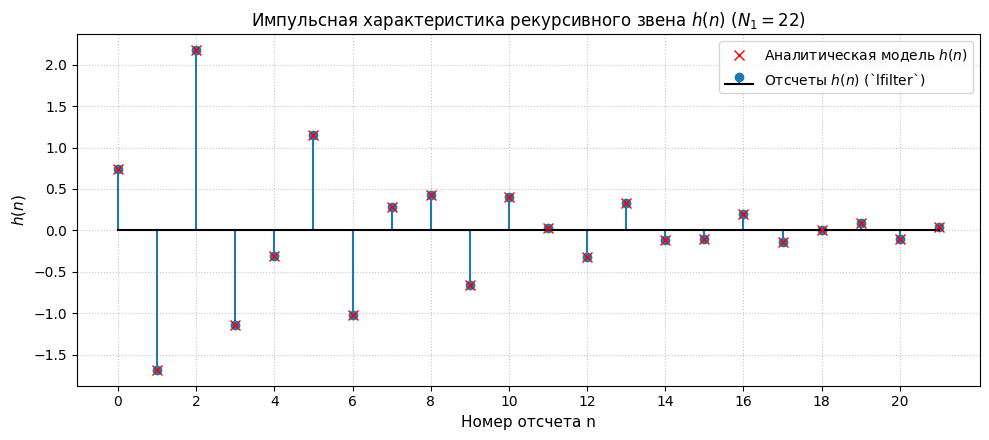

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Коэффициенты рекурсивного фильтра (Вариант 12)
b_coeff = np.array([0.74, -0.884892, 0.888], dtype=float)
a_coeff = np.array([1.0, 1.0778, 0.712], dtype=float)
N1 = 22
N2 = 32
fd_filter = 12000.0

# Моделирование единичного импульса u_0(n)
delta_in = np.zeros(N1, dtype=float)
delta_in[0] = 1.0
h_lfilter = signal.lfilter(b_coeff, a_coeff, delta_in)
n_h = np.arange(N1)

# Аналитический расчет параметров ИХ
h0 = b_coeff[0]
h1 = b_coeff[1] - a_coeff[1] * h0
h2 = b_coeff[2] - a_coeff[1] * h1 - a_coeff[2] * h0

poles = np.roots(a_coeff)
p1 = poles[0]
r_star = np.abs(p1)
phi_star = np.angle(p1)

A0 = b_coeff[2] / a_coeff[2]
u = (b_coeff[0] - A0) / 2.0
v = (u * p1.real - h1 / 2.0) / p1.imag

# Формула для всех n >= 0
h_analyt_full = 2.0 * (r_star ** n_h) * (u * np.cos(phi_star * n_h) - v * np.sin(phi_star * n_h))
h_analyt_full[0] += A0

# Тригонометрическая форма для n >= 1
D1 = h1
D2 = (h2 / r_star - D1 * np.cos(phi_star)) / np.sin(phi_star)
h_trig = np.zeros(N1, dtype=float)
h_trig[0] = h0
h_trig[1:] = (r_star ** (n_h[1:] - 1)) * (D1 * np.cos(phi_star * (n_h[1:] - 1)) + D2 * np.sin(phi_star * (n_h[1:] - 1)))

max_diff_full = np.max(np.abs(h_lfilter - h_analyt_full))
max_diff_trig = np.max(np.abs(h_lfilter - h_trig))

print(f"Отсчеты h(0) = {h_lfilter[0]:.6f}, h(1) = {h_lfilter[1]:.6f}, h(2) = {h_lfilter[2]:.6f}")
print(f"Полюс p1: модуль r_* = {r_star:.6f}, аргумент phi_* = {phi_star:.6f} рад ({phi_star/np.pi:.6f}*pi)")
print(f"Выделенная целая часть A0 = {A0:.6f}")
print(f"Максимальное расхождение lfilter и общей формулы: {max_diff_full:.3e}")
print(f"Максимальное расхождение lfilter и тригонометрической формы: {max_diff_trig:.3e}")

# Построение графика импульсной характеристики
fig, ax = plt.subplots(figsize=(10, 4.5))
markerline, stemlines, baseline = ax.stem(n_h, h_lfilter, basefmt="k-", label=r"Отсчеты $h(n)$ (`lfilter`)")
plt.setp(markerline, markersize=6, color="#1f77b4")
plt.setp(stemlines, linewidth=1.5, color="#1f77b4")
ax.plot(n_h, h_analyt_full, "rx", markersize=7, label=r"Аналитическая модель $h(n)$")
ax.set_title(r"Импульсная характеристика рекурсивного звена $h(n)$ ($N_1 = 22$)", fontsize=12)
ax.set_xlabel("Номер отсчета n", fontsize=11)
ax.set_ylabel(r"$h(n)$", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.7)
ax.set_xticks(np.arange(0, N1, 2))
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


##### Аналитическое описание импульсной характеристики и выводы
1. **Начальные условия и рекурсия:** при подаче единичного импульса $x(n) = u_0(n)$ и нулевых начальных условиях ($y(-1) = y(-2) = 0$, $x(-1) = x(-2) = 0$) разностное уравнение дает первые отсчеты:
   $$h(0) = b_0 = 0.74,$$
   $$h(1) = b_1 - a_1 h(0) = -0.884892 - 1.0778 \cdot 0.74 = -1.682464,$$
   $$h(2) = b_2 - a_1 h(1) - a_2 h(0) = 0.888 - 1.0778 \cdot (-1.682464) - 0.712 \cdot 0.74 = 2.174480.$$
   При всех $n \ge 3$ входной сигнал и его задержанные версии равны нулю ($x(n) = x(n-1) = x(n-2) = 0$), поэтому выполняется однородное разностное уравнение:
   $$h(n) + a_1 h(n-1) + a_2 h(n-2) = 0, \quad n \ge 3.$$

2. **Выделение целой части передаточной функции:** поскольку степени числителя и знаменателя $H(z)$ равны 2, выделяется постоянное слагаемое $A_0 = b_2 / a_2 = 0.888 / 0.712 \approx 1.247191$:
   $$H(z) = A_0 + \frac{A_1}{1 - p_1 z^{-1}} + \frac{A_2}{1 - p_2 z^{-1}},$$
   где полюсы равны $p_{1,2} = -0.538900 \pm j 0.649297 = r_* e^{\pm j\varphi_*}$ с параметрами $r_* = \sqrt{a_2} \approx 0.843801$ и $\varphi_* \approx 2.263549\text{ рад} \approx 0.720510\pi$.
   Из предельного перехода при $z \to \infty$ ($h(0) = A_0 + A_1 + A_2$) и значения $h(1) = A_1 p_1 + A_2 p_2$ получены коэффициенты $A_{1,2} = -0.253596 \pm j 1.506082$.

3. **Точная аналитическая формула:**
   для всех $n \ge 0$:
   $$h(n) = 1.247191\,\delta(n) + 2(0.843801)^n \big(-0.253596\cos(2.263549n) - 1.506082\sin(2.263549n)\big).$$
   Эквивалентная форма для $n \ge 1$:
   $$h(n) = (0.843801)^{n-1} \big(-1.682464\cos(2.263549(n-1)) + 1.952573\sin(2.263549(n-1))\big), \quad h(0) = 0.74.$$
   Численное сопоставление подтверждает совпадение аналитических формул с результатом `lfilter` с погрешностью порядка $10^{-15}$.

4. **Действительная длина импульсной характеристики:** в действительности длина импульсной характеристики рекурсивного (БИХ) звена равна **бесконечности** ($n \in [0, \infty)$). Однако ввиду устойчивости системы ($|p_{1,2}| = 0.843801 < 1$) свободные колебания экспоненциально затухают, поэтому для численного моделирования последовательность ограничивается конечной длиной $N_1 = 22$ отсчета.


#### Пункт 2. Реакция системы по формуле свёртки
Формируется дискретный прямоугольный импульс $x(n)$ длины $N_2 = 32$ с активной длительностью $\mathrm{int}(N_2/2) = 16$ отсчетов. Вычисляется линейная свертка $x(n)$ с усеченной импульсной характеристикой $h(n)$ ($N_1 = 22$). Отображается полная свертка и реакция $y_1(n)$, усеченная до длины входного воздействия.


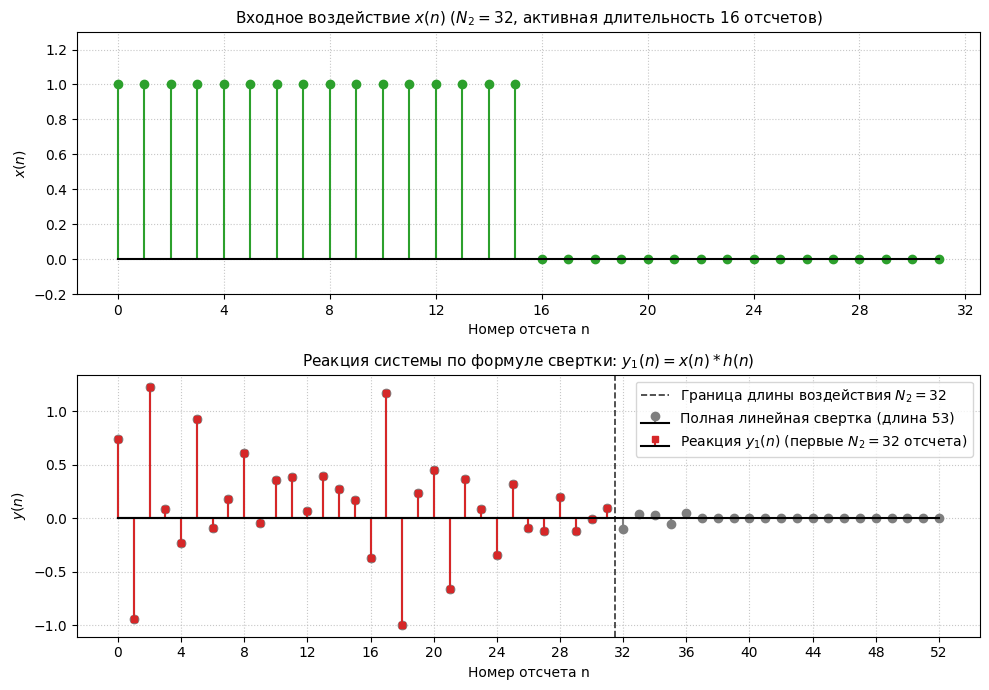

Длина входной последовательности x(n): 32
Длина полной линейной свертки: 53
Длина усеченной реакции y1(n): 32


In [2]:
# Формирование входного воздействия
n_x = np.arange(N2)
active_length = int(np.rint(N2 / 2.0)) # 16 отсчетов
x_rect = np.where(n_x < active_length, 1.0, 0.0)

# Вычисление полной линейной свертки
y_conv_full = np.convolve(x_rect, h_lfilter, mode="full")
n_conv_full = np.arange(len(y_conv_full))

# Усечение реакции до длины воздействия N2 = 32
y1 = y_conv_full[:N2]
n_y1 = np.arange(N2)

# Визуализация воздействия и реакции
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=False)

# График воздействия
axes[0].stem(n_x, x_rect, basefmt="k-", linefmt="#2ca02c", markerfmt="o")
axes[0].set_title(r"Входное воздействие $x(n)$ ($N_2 = 32$, активная длительность 16 отсчетов)", fontsize=11)
axes[0].set_xlabel("Номер отсчета n", fontsize=10)
axes[0].set_ylabel(r"$x(n)$", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.7)
axes[0].set_ylim(-0.2, 1.3)
axes[0].set_xticks(np.arange(0, N2 + 1, 4))

# График реакции
axes[1].stem(n_conv_full, y_conv_full, basefmt="k-", linefmt="#7f7f7f", markerfmt="o",
             label=f"Полная линейная свертка (длина {len(y_conv_full)})")
markerline, stemlines, baseline = axes[1].stem(n_y1, y1, basefmt="k-", linefmt="#d62728", markerfmt="s",
                                              label=r"Реакция $y_1(n)$ (первые $N_2 = 32$ отсчета)")
plt.setp(markerline, markersize=5)
axes[1].axvline(N2 - 0.5, color="black", linestyle="--", linewidth=1.2, alpha=0.8,
                label=r"Граница длины воздействия $N_2 = 32$")
axes[1].set_title(r"Реакция системы по формуле свертки: $y_1(n) = x(n) * h(n)$", fontsize=11)
axes[1].set_xlabel("Номер отсчета n", fontsize=10)
axes[1].set_ylabel(r"$y(n)$", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.7)
axes[1].set_xticks(np.arange(0, len(y_conv_full) + 1, 4))
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

print(f"Длина входной последовательности x(n): {len(x_rect)}")
print(f"Длина полной линейной свертки: {len(y_conv_full)}")
print(f"Длина усеченной реакции y1(n): {len(y1)}")


##### Анализ параметров свертки и ответы на контрольные вопросы
1. **Длина импульса $x(n)$:** Полная длина входной последовательности составляет $N_2 = 32$ отсчета. При этом длительность активной (ненулевой единичной) части прямоугольного импульса равна $\mathrm{int}(N_2/2) = 16$ отсчетам ($n \in [0, 15]$), а отсчеты $n \in [16, 31]$ равны нулю.

2. **Длина свертки аналитически и по графику:**
   - *Аналитическая длина* свертки двух последовательностей длинами $N_2 = 32$ и $N_1 = 22$ равна:
     $$L_{\mathrm{conv}} = N_2 + N_1 - 1 = 32 + 22 - 1 = 53\text{ отсчета } (n = 0, \dots, 52).$$
   - *Длина по графику (ненулевая часть):* поскольку входной сигнал становится тождественно равным нулю при $n \ge 16$, ненулевой отклик формируется суммой активной части ($16$ отсчетов) и импульсной характеристики ($22$ отсчета). Последний ненулевой отсчет свертки располагается в точке $n_{\max} = 15 + 21 = 36$. Следовательно, ненулевая часть свертки по графику занимает ровно:
     $$L_{\mathrm{active}} = 16 + 22 - 1 = 37\text{ отсчетов } (n = 0, \dots, 36),$$
     а завершающие 16 отсчетов ($n = 37, \dots, 52$) строго равны нулю.

3. **Причина ограничения реакции до длины воздействия:** реакцию ограничивают первыми $N_2 = 32$ отсчетами для исследования динамики системы непосредственно на временном интервале наблюдения входного сигнала $n \in [0, N_2-1]$, а также для корректного поточечного сопоставления с решением разностного уравнения $y_2(n)$, формируемым при подаче вектора входа длины $N_2$.

Полученная свёртка длины 53 является полной линейной свёрткой входного воздействия и усечённой импульсной характеристики длины 22. Полная реакция исходной рекурсивной системы имеет бесконечную длительность.


#### Пункт 3. Реакция системы по разностному уравнению
Вычисляется реакция $y_2(n)$ рекурсивного звена второго порядка на воздействие $x(n)$ путем численного решения разностного уравнения при нулевых начальных условиях. Проводится сопоставление $y_2(n)$ с реакцией $y_1(n)$, полученной через свертку.


Длина вектора воздействия x(n): 32
Длина вектора реакции y2(n):    32
Максимальное расхождение y1 и y2 на интервале n in [0, 21]: 3.886e-16
Максимальное расхождение y1 и y2 на интервале n in [22, 31]: 0.035218


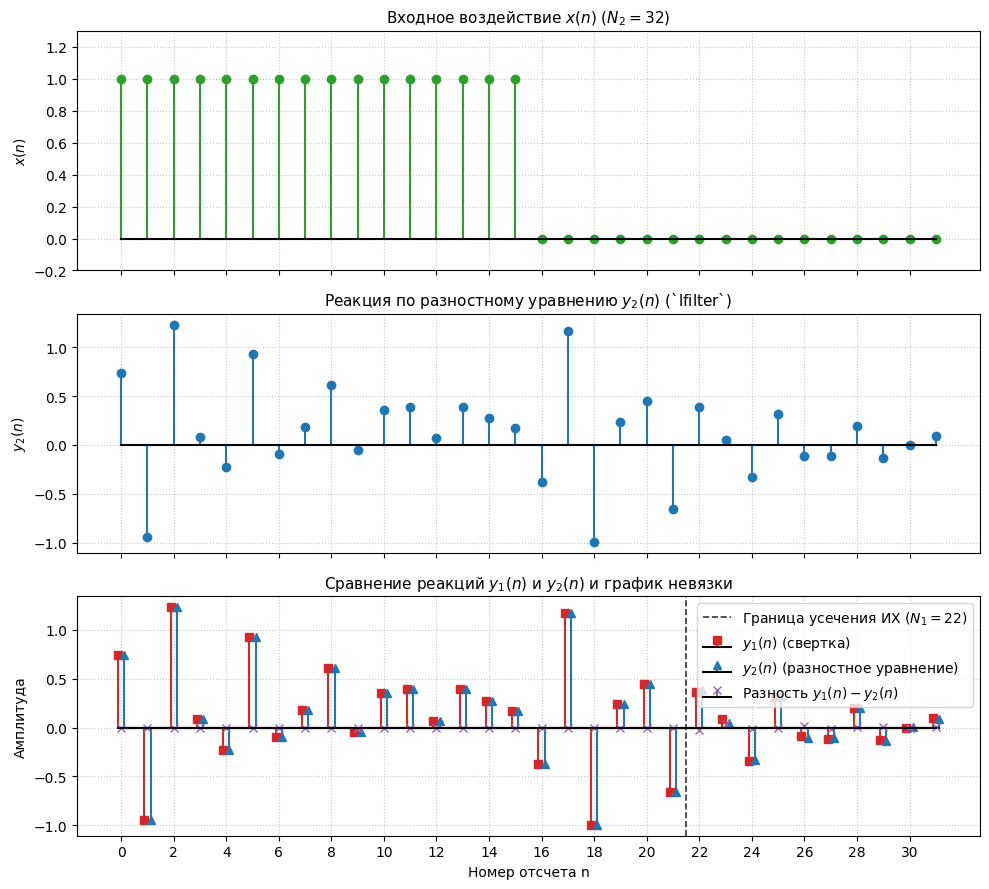

In [3]:
# Вычисление реакции по разностному уравнению через lfilter
y2 = signal.lfilter(b_coeff, a_coeff, x_rect)
diff_y = y1 - y2
max_discrepancy = np.max(np.abs(diff_y))

print(f"Длина вектора воздействия x(n): {len(x_rect)}")
print(f"Длина вектора реакции y2(n):    {len(y2)}")
print(f"Максимальное расхождение y1 и y2 на интервале n in [0, 21]: {np.max(np.abs(diff_y[:22])):.3e}")
print(f"Максимальное расхождение y1 и y2 на интервале n in [22, 31]: {np.max(np.abs(diff_y[22:])):.6f}")

# Построение дискретных stem-графиков
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# График воздействия
axes[0].stem(n_x, x_rect, basefmt="k-", linefmt="#2ca02c", markerfmt="o")
axes[0].set_title(r"Входное воздействие $x(n)$ ($N_2 = 32$)", fontsize=11)
axes[0].set_ylabel(r"$x(n)$", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.7)
axes[0].set_ylim(-0.2, 1.3)

# График реакции по разностному уравнению
axes[1].stem(n_x, y2, basefmt="k-", linefmt="#1f77b4", markerfmt="o")
axes[1].set_title(r"Реакция по разностному уравнению $y_2(n)$ (`lfilter`)", fontsize=11)
axes[1].set_ylabel(r"$y_2(n)$", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.7)

# Сопоставление реакций и график невязки
axes[2].stem(n_x - 0.12, y1, basefmt="k-", linefmt="#d62728", markerfmt="s", label=r"$y_1(n)$ (свертка)")
axes[2].stem(n_x + 0.12, y2, basefmt="k-", linefmt="#1f77b4", markerfmt="^", label=r"$y_2(n)$ (разностное уравнение)")
axes[2].stem(n_x, diff_y, basefmt="k-", linefmt="#9467bd", markerfmt="x", label=r"Разность $y_1(n) - y_2(n)$")
axes[2].axvline(N1 - 0.5, color="black", linestyle="--", linewidth=1.2, alpha=0.8,
                label=r"Граница усечения ИХ ($N_1 = 22$)")
axes[2].set_title(r"Сравнение реакций $y_1(n)$ и $y_2(n)$ и график невязки", fontsize=11)
axes[2].set_xlabel("Номер отсчета n", fontsize=10)
axes[2].set_ylabel("Амплитуда", fontsize=10)
axes[2].grid(True, linestyle=":", alpha=0.7)
axes[2].set_xticks(np.arange(0, N2, 2))
axes[2].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


##### Анализ результатов и сопоставление реакций
1. **Разностное уравнение рекурсивного звена 2-го порядка:**
   с подставленными численными коэффициентами варианта 12 разностное уравнение имеет вид:
   $$y(n) = 0.74\,x(n) - 0.884892\,x(n-1) + 0.888\,x(n-2) - 1.0778\,y(n-1) - 0.712\,y(n-2).$$

2. **Длины воздействия и реакции:**
   - Длина входного вектора воздействия $x(n)$ равна $N_2 = 32$ отсчетам.
   - Длина рассчитанной реакции $y_2(n)$ также равна $N_2 = 32$ отсчетам.

3. **Сравнение реакций $y_1(n)$ и $y_2(n)$:**
   - На начальном интервале $0 \le n < N_1 = 22$ значения реакций $y_1(n)$ и $y_2(n)$ совпадают с машинной точностью (погрешность $\sim 10^{-16}$). Это обусловлено тем, что для формирования первых 22 отсчетов свертки требуются только начальные 22 отсчета импульсной характеристики.
   - На интервале $22 \le n \le 31$ наблюдается небольшое расхождение между реакциями (максимальная абсолютная разность составляет $0.035218$). Причина заключается в том, что в алгоритме свертки $y_1(n)$ использовалась усеченная ИХ длины $N_1 = 22$, тогда как разностное уравнение $y_2(n)$ реализует истинную рекурсивную фильтрацию с бесконечной импульсной характеристикой, учитывая затухающие колебания системы за пределами 22-го отсчета.

Длина рассчитанного вектора выходных отсчётов составляет 32, поскольку рассматривается интервал наблюдения, совпадающий с длиной воздействия. При этом теоретическая реакция рекурсивной системы на конечный входной сигнал продолжается после окончания воздействия и постепенно затухает, поскольку импульсная характеристика системы бесконечна.


#### Пункт 4. Нули и полюсы передаточной функции
Вычисляются корни числителя (нули) и знаменателя (полюсы) передаточной функции $H(z)$ с представлением в алгебраической и показательной формах. Передаточная функция факторизуется в виде произведения элементарных сомножителей первого порядка.


In [4]:
zeros_z, poles_z, gain_z = signal.tf2zpk(b_coeff, a_coeff)

print("=" * 70)
print(f"{'Тип корня':<10} | {'Алгебраическая форма':<22} | {'Модуль':<10} | {'Аргумент (рад)':<14} | {'Аргумент (доли pi)'}")
print("-" * 70)
for idx, z in enumerate(zeros_z, start=1):
    mod_z = np.abs(z)
    arg_z = np.angle(z)
    print(f"Ноль z_{idx:<4} | {z.real:+.6f} {z.imag:+.6f}j | {mod_z:<10.6f} | {arg_z:<14.6f} | {arg_z/np.pi:+.6f}*pi")
for idx, p in enumerate(poles_z, start=1):
    mod_p = np.abs(p)
    arg_p = np.angle(p)
    print(f"Полюс p_{idx:<3} | {p.real:+.6f} {p.imag:+.6f}j | {mod_p:<10.6f} | {arg_p:<14.6f} | {arg_p/np.pi:+.6f}*pi")
print("=" * 70)


Тип корня  | Алгебраическая форма   | Модуль     | Аргумент (рад) | Аргумент (доли pi)
----------------------------------------------------------------------
Ноль z_1    | +0.597900 +0.917886j | 1.095445   | 0.993446       | +0.316224*pi
Ноль z_2    | +0.597900 -0.917886j | 1.095445   | -0.993446      | -0.316224*pi
Полюс p_1   | -0.538900 +0.649297j | 0.843801   | 2.263549       | +0.720510*pi
Полюс p_2   | -0.538900 -0.649297j | 0.843801   | -2.263549      | -0.720510*pi


##### Аналитическое представление нулей, полюсов и передаточной функции

#### Сводная таблица нулей и полюсов

| Корень | Алгебраическая форма | Модуль $r$ | Аргумент $\theta$ (рад) | Аргумент $\theta/\pi$ |
| :--- | :--- | :--- | :--- | :--- |
| Ноль $z_1$ | $+0.597900 + 0.917886j$ | $1.095445$ | $+0.993446$ | $+0.316224\pi$ |
| Ноль $z_2$ | $+0.597900 - 0.917886j$ | $1.095445$ | $-0.993446$ | $-0.316224\pi$ |
| Полюс $p_1$ | $-0.538900 + 0.649297j$ | $0.843801$ | $+2.263549$ | $+0.720510\pi$ |
| Полюс $p_2$ | $-0.538900 - 0.649297j$ | $0.843801$ | $-2.263549$ | $-0.720510\pi$ |

Связь между алгебраической формой $z = x + jy$ и показательной формой $z = r e^{j\theta}$ определяется соотношениями Эйлера:
$$r = \sqrt{x^2 + y^2}, \qquad \theta = \operatorname{atan2}(y, x), \qquad x = r\cos\theta, \qquad y = r\sin\theta.$$

Факторизованная форма передаточной функции в виде произведения простейших сомножителей:
$$H(z) = 0.74\,\frac{\left(1 - 1.095445 e^{j 0.316224\pi} z^{-1}\right)\left(1 - 1.095445 e^{-j 0.316224\pi} z^{-1}\right)}{\left(1 - 0.843801 e^{j 0.720510\pi} z^{-1}\right)\left(1 - 0.843801 e^{-j 0.720510\pi} z^{-1}\right)}.$$


#### Пункт 5. Карта нулей и полюсов
Строится геометрическое распределение нулей и полюсов передаточной функции на комплексной $z$-плоскости относительно единичной окружности $|z| = 1$. Анализируется устойчивость системы.


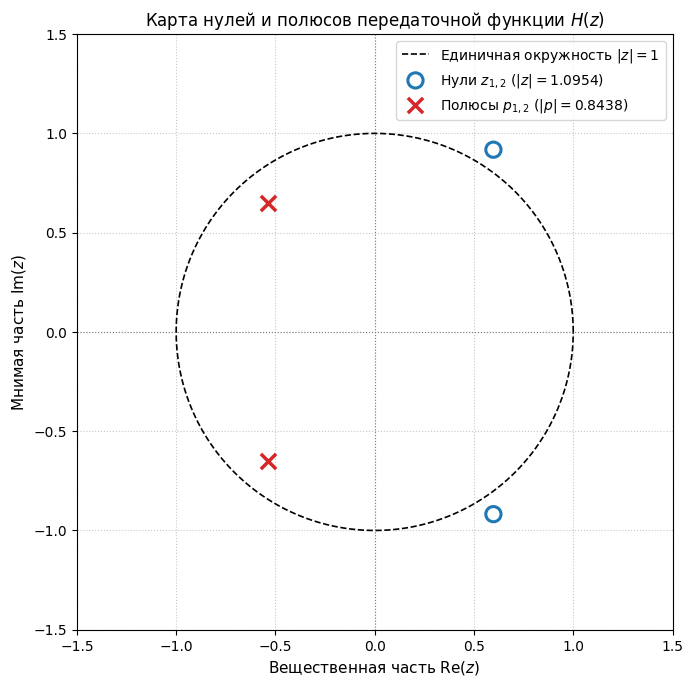

In [5]:
# Построение комплексной z-плоскости
theta_circ = np.linspace(0.0, 2.0 * np.pi, 1000)
unit_x = np.cos(theta_circ)
unit_y = np.sin(theta_circ)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(unit_x, unit_y, "k--", linewidth=1.2, label=r"Единичная окружность $|z|=1$")
ax.axhline(0.0, color="gray", linewidth=0.8, linestyle=":")
ax.axvline(0.0, color="gray", linewidth=0.8, linestyle=":")

# Отображение нулей и полюсов
ax.scatter(zeros_z.real, zeros_z.imag, s=120, facecolors="none", edgecolors="#1f77b4",
           linewidths=2.2, label=r"Нули $z_{1,2}$ ($|z|=1.0954$)", zorder=4)
ax.scatter(poles_z.real, poles_z.imag, s=120, marker="x", color="#d62728",
           linewidths=2.5, label=r"Полюсы $p_{1,2}$ ($|p|=0.8438$)", zorder=4)

# Оформление графика
ax.set_title(r"Карта нулей и полюсов передаточной функции $H(z)$", fontsize=12)
ax.set_xlabel(r"Вещественная часть $\operatorname{Re}(z)$", fontsize=11)
ax.set_ylabel(r"Мнимая часть $\operatorname{Im}(z)$", fontsize=11)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, linestyle=":", alpha=0.7)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


##### Анализ карты нулей и полюсов
1. **Устойчивость рекурсивного звена:** Причинная дискретная система является устойчивой, поскольку оба комплексно-сопряженных полюса $p_{1,2} = -0.538900 \pm j0.649297$ имеют модуль $|p_{1,2}| = 0.843801 < 1$ и расположены строго **внутри единичной окружности**.

2. **Соответствие координатам из пункта 4:** Геометрические координаты нулей ($0.597900 \pm j0.917886$) и полюсов ($-0.538900 \pm j0.649297$) на комплексной плоскости полностью совпадают со значениями, аналитически и численно рассчитанными в пункте 4. Нули располагаются вне единичной окружности на расстоянии $1.095445$ от начала координат.


#### Пункт 6. АЧХ и ФЧХ в шкале нормированных частот
Вычисляются амплитудно-частотная (АЧХ) и фазочастотная (ФЧХ) характеристики фильтра в основной полосе нормированных частот $\hat{\omega} \in [0, \pi]$ рад/отсчет с помощью `scipy.signal.freqz`.


Минимум АЧХ: A_min = 0.060954 на частоте omega = 0.313477*pi
Максимум АЧХ: A_max = 8.819478 на частоте omega = 0.730347*pi


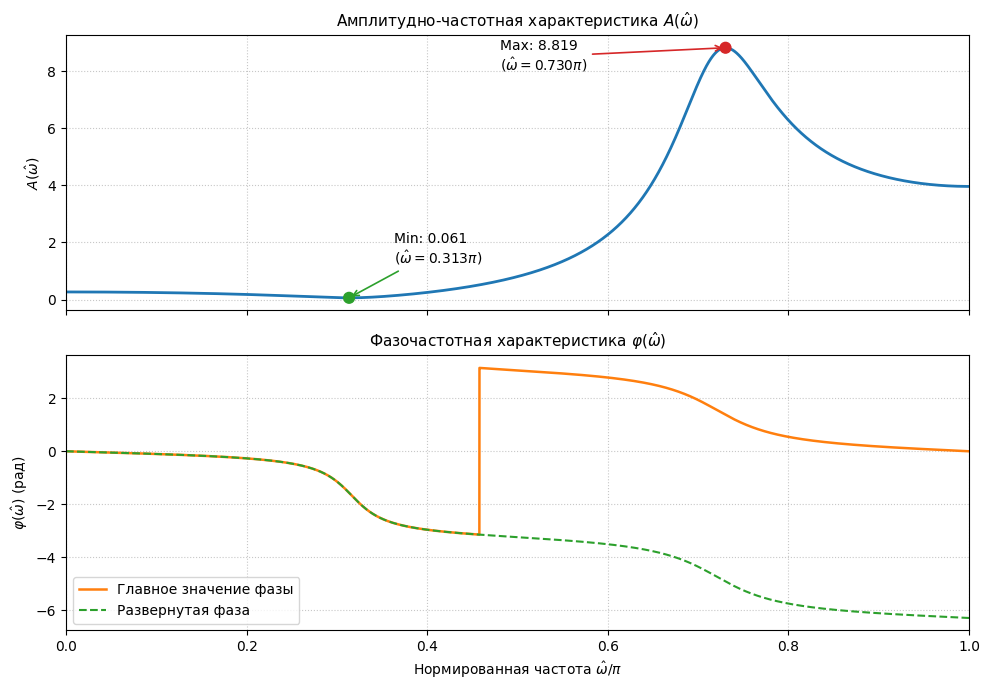

In [20]:
omega_grid = np.linspace(0, np.pi, 8193)

omega_norm, H_resp = signal.freqz(
    b_coeff, a_coeff, worN=omega_grid
)
A_norm = np.abs(H_resp)
phi_norm = np.angle(H_resp)
phi_unwrapped = np.unwrap(phi_norm)

# Поиск экстремумов АЧХ
idx_min = int(np.argmin(A_norm))
idx_max = int(np.argmax(A_norm))

omega_min_pi = omega_norm[idx_min] / np.pi
omega_max_pi = omega_norm[idx_max] / np.pi

print(f"Минимум АЧХ: A_min = {A_norm[idx_min]:.6f} на частоте omega = {omega_min_pi:.6f}*pi")
print(f"Максимум АЧХ: A_max = {A_norm[idx_max]:.6f} на частоте omega = {omega_max_pi:.6f}*pi")

# Построение графиков АЧХ и ФЧХ
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# График АЧХ
axes[0].plot(omega_norm / np.pi, A_norm, color="#1f77b4", linewidth=2.0, label="АЧХ")
axes[0].scatter([omega_min_pi, omega_max_pi], [A_norm[idx_min], A_norm[idx_max]],
                color=["#2ca02c", "#d62728"], s=60, zorder=5)
axes[0].annotate(f"Min: {A_norm[idx_min]:.3f}\n($\\hat{{\\omega}}={omega_min_pi:.3f}\\pi$)",
                 xy=(omega_min_pi, A_norm[idx_min]), xytext=(omega_min_pi + 0.05, A_norm[idx_min] + 1.2),
                 arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.2))
axes[0].annotate(f"Max: {A_norm[idx_max]:.3f}\n($\\hat{{\\omega}}={omega_max_pi:.3f}\\pi$)",
                 xy=(omega_max_pi, A_norm[idx_max]), xytext=(omega_max_pi - 0.25, A_norm[idx_max] - 0.8),
                 arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.2))
axes[0].set_title(r"Амплитудно-частотная характеристика $A(\hat{\omega})$", fontsize=11)
axes[0].set_ylabel(r"$A(\hat{\omega})$", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.7)

# График ФЧХ
axes[1].plot(omega_norm / np.pi, phi_norm, color="#ff7f0e", linewidth=1.8, label="Главное значение фазы")
axes[1].plot(omega_norm / np.pi, phi_unwrapped, color="#2ca02c", linestyle="--", linewidth=1.5, label="Развернутая фаза")
axes[1].set_title(r"Фазочастотная характеристика $\varphi(\hat{\omega})$", fontsize=11)
axes[1].set_xlabel(r"Нормированная частота $\hat{\omega}/\pi$", fontsize=10)
axes[1].set_ylabel(r"$\varphi(\hat{\omega})$ (рад)", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.7)
axes[1].set_xlim(0, 1)
axes[1].legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.show()


##### Анализ частотных характеристик в шкале нормированных частот
1. **Границы основной полосы частот:** Основная полоса нормированных частот дискретной системы ограничена диапазоном $\hat{\omega} \in [0, \pi]$ рад/отсчет, где точка $\hat{\omega} = \pi$ соответствует частоте Найквиста.

2. **Соответствие карты нулей и полюсов виду АЧХ:**
   - Нули передаточной функции имеют аргумент $\pm 0.316224\pi$ и модуль $1.095445$. Их близость к единичной окружности приводит к формированию глубокого провала (минимума) АЧХ до величины $A_{\min} \approx 0.060954$ на частоте $\hat{\omega} \approx 0.313477\pi$.
   - Полюсы передаточной функции имеют аргумент $\pm 0.720510\pi$ и модуль $0.843801$. Их близость к единичной окружности приводит к формированию выраженного резонансного подъёма АЧХ (максимума) до значения $A_{max}\approx 8.819478$ на частоте $\hat \omega \approx 0.730347\pi$. Расположение полюсов строго внутри единичной окружности обеспечивает устойчивость исследуемой системы.

3. **Скачок ФЧХ на $\pi$**: Истинное изменение фазы на $\pi$ связано с прохождением через частоту, на которой АЧХ обращается в ноль ($A(\hat \omega)=0$), что для рассматриваемой системы означало бы расположение нуля передаточной функции непосредственно на единичной окружности ($|z_i|=1$). В исследуемом варианте модули нулей равны $|z_{1,2}|=1.095445>1$, поэтому АЧХ не обращается в ноль и скачка фазы на $\pi$ не возникает.
В области провала АЧХ фаза резко убывает: при приближении к частоте минимума $\hat \omega\approx0.313477\pi$ она достигает значения около $-1.564$ рад ($\approx-0.498\pi$). Это связано с частотной зависимостью аргумента комплексной передаточной функции вблизи нулей.
На графике главного значения фазы также наблюдается переброс с $-\pi$ на $+\pi$ при $\hat \omega\approx0.457861\pi$ (около $2747.16$ Гц). Он обусловлен ограничением значения аргумента диапазоном $(-\pi,\pi]$ и представляет собой изменение отображения фазы на $2\pi$, а не физический разрыв фазочастотной характеристики. На графике развёрнутой фазы этот переброс отсутствует: фаза непрерывно уменьшается и достигает значения $-2\pi$ при $\hat \omega=\pi$.

4. **Подавление составляющих воздействия**: Исследуемая система ослабляет частотные составляющие, для которых АЧХ меньше единицы. В частности, при $\hat \omega=0$ значение АЧХ составляет $A(0)\approx0.266366$. После глубокого провала при $\hat \omega \approx0.313477\pi$ амплитуда постепенно увеличивается, однако остаётся меньше единицы примерно до $\hat \omega \approx0.521360\pi$. Начиная с этой частоты АЧХ превышает единицу, то есть система усиливает соответствующие составляющие сигнала. Наиболее выраженное усиление наблюдается в области резонансного максимума при $\hat \omega \approx0.730347\pi$.


#### Пункт 7. АЧХ и ФЧХ в шкале частот (Гц)
Строятся графики АЧХ и ФЧХ в шкале физических частот $f$ (Гц) при заданной частоте дискретизации фильтра $f_{\mathrm{d}} = 12000$ Гц.


Частота минимума АЧХ: f_min = 1880.86 Гц
Частота максимума АЧХ: f_max = 4382.08 Гц


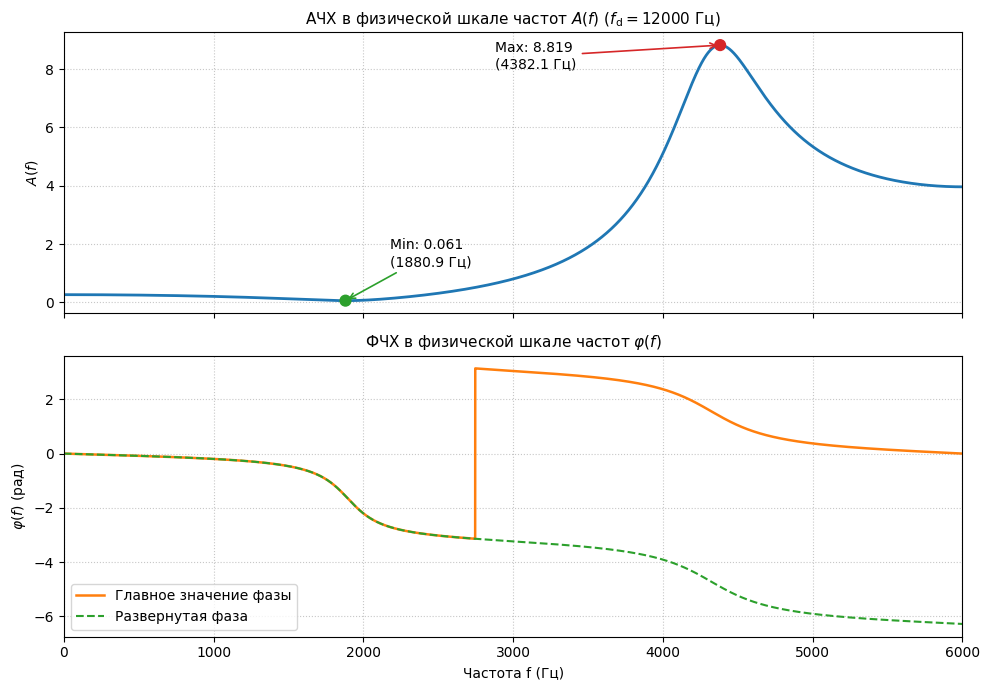

In [7]:
# Пересчет нормированной частоты в физическую частоту в Гц
freq_hz = omega_norm * fd_filter / (2.0 * np.pi)
f_min_hz = freq_hz[idx_min]
f_max_hz = freq_hz[idx_max]

print(f"Частота минимума АЧХ: f_min = {f_min_hz:.2f} Гц")
print(f"Частота максимума АЧХ: f_max = {f_max_hz:.2f} Гц")

# Построение графиков АЧХ и ФЧХ в Гц
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# График АЧХ
axes[0].plot(freq_hz, A_norm, color="#1f77b4", linewidth=2.0)
axes[0].scatter([f_min_hz, f_max_hz], [A_norm[idx_min], A_norm[idx_max]],
                color=["#2ca02c", "#d62728"], s=60, zorder=5)
axes[0].annotate(f"Min: {A_norm[idx_min]:.3f}\n({f_min_hz:.1f} Гц)",
                 xy=(f_min_hz, A_norm[idx_min]), xytext=(f_min_hz + 300, A_norm[idx_min] + 1.2),
                 arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.2))
axes[0].annotate(f"Max: {A_norm[idx_max]:.3f}\n({f_max_hz:.1f} Гц)",
                 xy=(f_max_hz, A_norm[idx_max]), xytext=(f_max_hz - 1500, A_norm[idx_max] - 0.8),
                 arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.2))
axes[0].set_title(r"АЧХ в физической шкале частот $A(f)$ ($f_{\mathrm{d}} = 12000$ Гц)", fontsize=11)
axes[0].set_ylabel(r"$A(f)$", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.7)

# График ФЧХ
axes[1].plot(freq_hz, phi_norm, color="#ff7f0e", linewidth=1.8, label="Главное значение фазы")
axes[1].plot(freq_hz, phi_unwrapped, color="#2ca02c", linestyle="--", linewidth=1.5, label="Развернутая фаза")
axes[1].set_title(r"ФЧХ в физической шкале частот $\varphi(f)$", fontsize=11)
axes[1].set_xlabel("Частота f (Гц)", fontsize=10)
axes[1].set_ylabel(r"$\varphi(f)$ (рад)", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.7)
axes[1].set_xlim(0, fd_filter / 2.0)
axes[1].legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.show()


##### Анализ частотных характеристик в физической шкале частот
1. **Границы основной полосы частот:** При частоте дискретизации $f_{\mathrm{d}} = 12000$ Гц основная полоса частот дискретной системы лежит в интервале от $0$ до частоты Найквиста:
   $$0 \le f \le \frac{f_{\mathrm{d}}}{2} = 6000\text{ Гц}.$$

2. **Соответствие между нормированной и физической шкалами:** Линейный пересчет частот задается соотношением:
   $$f = \frac{\hat{\omega}}{2\pi} f_{\mathrm{d}}.$$
   Провал АЧХ при $\hat{\omega} \approx 0.313477\pi$ соответствует физической частоте $f_{\min} \approx 1880.86$ Гц, а резонансный подъем при $\hat{\omega} \approx 0.730347\pi$ — частоте $f_{\max} \approx 4382.08$ Гц. Графики в шкале частот в точности сохраняют форму характеристик из пункта 6 с линейным масштабированием горизонтальной оси.


### Часть 2. Дискретное преобразование Фурье


#### Пункт 1. Графики последовательности на интервале N = 64
Формируется двухчастотная периодическая дискретная последовательность длины $N = 64$ при $f_{\mathrm{d}} = 6000$ Гц, $T = 1/6000$ с, $A_1 = 1.12$, $A_2 = 2.24$, $f_1 = 750$ Гц, $f_2 = 1125$ Гц:
$$x(nT) = A_1 \cos(2\pi f_1 nT + \pi/4) + A_2 \cos(2\pi f_2 nT + \pi/8).$$
Строятся два дискретных stem-графика: в шкале дискретного нормированного времени $n$ и в шкале физического дискретного времени $nT$.

Рассматриваемая последовательность имеет фундаментальный период 16 отсчётов. Заданный интервал \(N=64\) содержит четыре таких периода и используется для выполнения ДПФ длины 64.

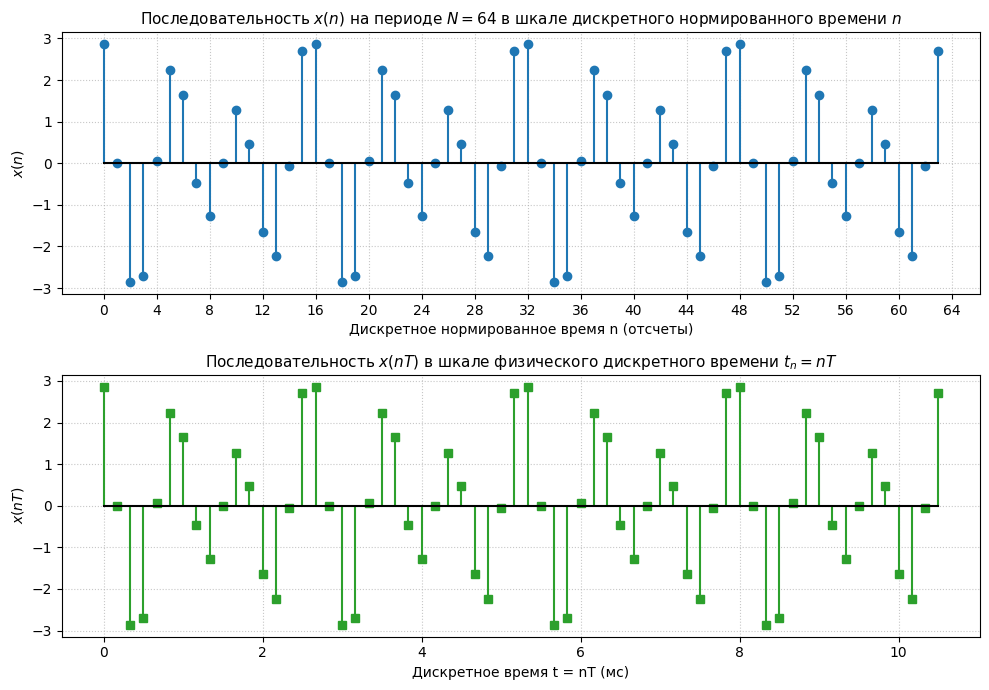

In [8]:
# Параметры последовательности (Вариант 12, Часть 2)
N_dft = 64
fd_signal = 6000.0
T_sampling = 1.0 / fd_signal
A1 = 1.12
A2 = 2.24
f1 = 750.0
f2 = 1125.0

n_seq = np.arange(N_dft)
t_seq = n_seq * T_sampling
x_periodic = A1 * np.cos(2.0 * np.pi * f1 * t_seq + np.pi / 4.0) + A2 * np.cos(2.0 * np.pi * f2 * t_seq + np.pi / 8.0)

# Построение дискретных stem-графиков
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

# Шкала дискретного нормированного времени n
axes[0].stem(n_seq, x_periodic, basefmt="k-", linefmt="#1f77b4", markerfmt="o")
axes[0].set_title(r"Последовательность $x(n)$ на периоде $N = 64$ в шкале дискретного нормированного времени $n$", fontsize=11)
axes[0].set_xlabel("Дискретное нормированное время n (отсчеты)", fontsize=10)
axes[0].set_ylabel(r"$x(n)$", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.7)
axes[0].set_xticks(np.arange(0, N_dft + 1, 4))

# Шкала дискретного времени nT (в миллисекундах)
axes[1].stem(t_seq * 1000.0, x_periodic, basefmt="k-", linefmt="#2ca02c", markerfmt="s")
axes[1].set_title(r"Последовательность $x(nT)$ в шкале физического дискретного времени $t_n = nT$", fontsize=11)
axes[1].set_xlabel("Дискретное время t = nT (мс)", fontsize=10)
axes[1].set_ylabel(r"$x(nT)$", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()


#### Пункт 2. Вычисление ОДПФ от ДПФ
Вычисляется прямое дискретное преобразование Фурье последовательности $x(n)$ длины $N = 64$, а затем восстанавливается исходная последовательность путем взятия обратного дискретного преобразования Фурье (ОДПФ). График восстановленной последовательности строится в шкале дискретного нормированного времени.


Максимальная погрешность восстановления x(n) через ОДПФ: 8.882e-16
Максимальная мнимая часть отсчетов после ОДПФ:       3.331e-16


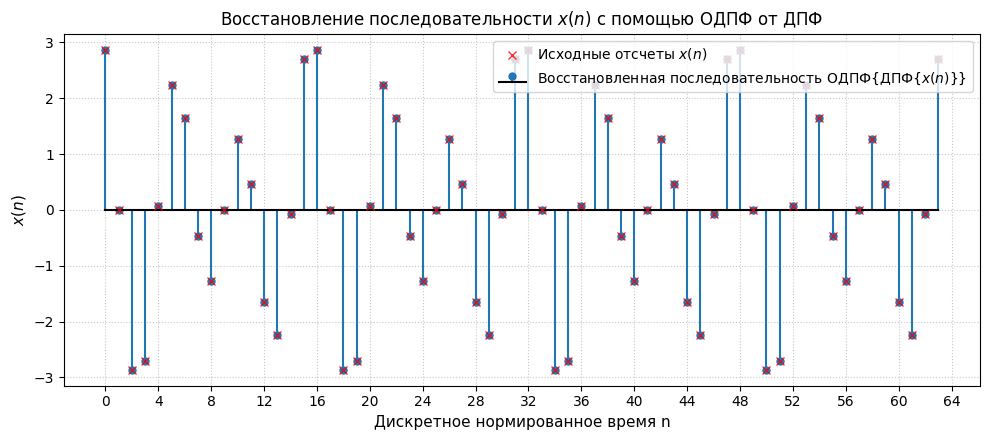

In [9]:
# Вычисление прямого и обратного ДПФ
X_dft = np.fft.fft(x_periodic)
x_restored_c = np.fft.ifft(X_dft)
x_restored = x_restored_c.real

max_idft_err = np.max(np.abs(x_periodic - x_restored))
max_imag_err = np.max(np.abs(x_restored_c.imag))

print(f"Максимальная погрешность восстановления x(n) через ОДПФ: {max_idft_err:.3e}")
print(f"Максимальная мнимая часть отсчетов после ОДПФ:       {max_imag_err:.3e}")

# Дискретный stem-график восстановленной последовательности
fig, ax = plt.subplots(figsize=(10, 4.5))
markerline, stemlines, baseline = ax.stem(n_seq, x_restored, basefmt="k-", linefmt="#1f77b4", markerfmt="o",
                                         label=r"Восстановленная последовательность $\mathrm{ОДПФ}\{\mathrm{ДПФ}\{x(n)\}\}$")
plt.setp(markerline, markersize=5)
ax.plot(n_seq, x_periodic, "rx", markersize=6, alpha=0.8, label=r"Исходные отсчеты $x(n)$")
ax.set_title(r"Восстановление последовательности $x(n)$ с помощью ОДПФ от ДПФ", fontsize=12)
ax.set_xlabel("Дискретное нормированное время n", fontsize=11)
ax.set_ylabel(r"$x(n)$", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.7)
ax.set_xticks(np.arange(0, N_dft + 1, 4))
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


##### Анализ обратимости ДПФ
Прямое и обратное преобразования Фурье образуют точную пару взаимно обратных линейных операторов. Вещественная часть восстановленной последовательности совпадает с исходными отсчетами $x(n)$ с машинной погрешностью порядка $10^{-15}$, а остаточная мнимая часть имеет порядок $10^{-16}$, что свидетельствует о строгой вычислительной корректности алгоритма.


#### Пункт 3. Амплитудный и фазовый спектры последовательности
Вычисляются комплексные коэффициенты ряда Фурье периодической последовательности $C(k) = \frac{1}{N}X(k)$. Для фазового спектра применяется пороговая фильтрация вычислительного шума в узлах с нулевой спектральной амплитудой. Строятся 4 графика `stem` (2×2) в шкалах нормированных и физических частот.


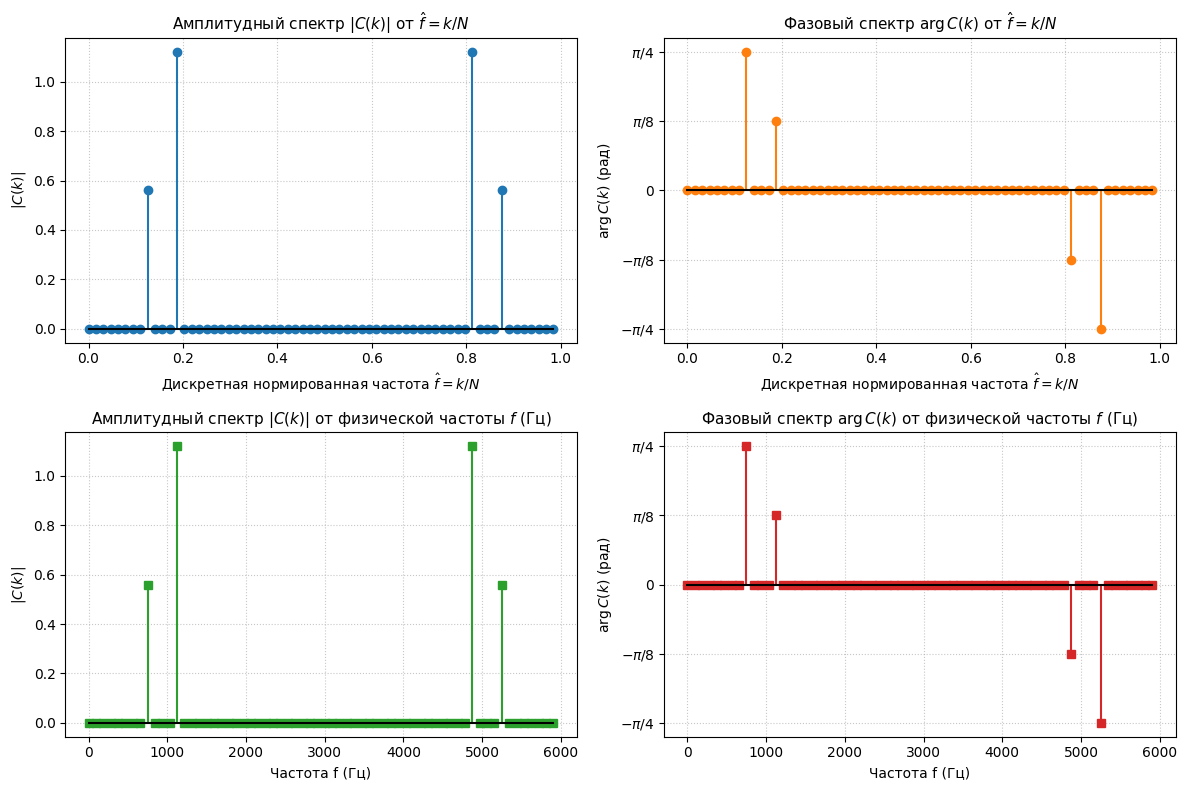

Спектральные пики периодической последовательности:
k =  8: f =  750.00 Гц | |C(k)| = 0.5600 | arg C(k) = +0.785398 рад
k = 12: f = 1125.00 Гц | |C(k)| = 1.1200 | arg C(k) = +0.392699 рад
k = 52: f = 4875.00 Гц | |C(k)| = 1.1200 | arg C(k) = -0.392699 рад
k = 56: f = 5250.00 Гц | |C(k)| = 0.5600 | arg C(k) = -0.785398 рад


In [10]:
# Коэффициенты ряда Фурье периодической последовательности
C_k = X_dft / N_dft
amplitude_spectrum = np.abs(C_k)

# Пороговая фильтрация фазового шума в нулевых отсчетах
phase_spectrum = np.where(amplitude_spectrum > 1e-10, np.angle(C_k), 0.0)

# Частотные шкалы
k_indices = np.arange(N_dft)
norm_freq = k_indices / float(N_dft)               # k / N
abs_freq = k_indices * (fd_signal / float(N_dft)) # k * fd / N

# Построение 4 графиков (2x2)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Амплитудный спектр от нормированной частоты
axes[0, 0].stem(norm_freq, amplitude_spectrum, basefmt="k-", linefmt="#1f77b4", markerfmt="o")
axes[0, 0].set_title(r"Амплитудный спектр $|C(k)|$ от $\hat{f} = k/N$", fontsize=11)
axes[0, 0].set_xlabel(r"Дискретная нормированная частота $\hat{f} = k/N$", fontsize=10)
axes[0, 0].set_ylabel(r"$|C(k)|$", fontsize=10)
axes[0, 0].grid(True, linestyle=":", alpha=0.7)

# 2. Фазовый спектр от нормированной частоты
axes[0, 1].stem(norm_freq, phase_spectrum, basefmt="k-", linefmt="#ff7f0e", markerfmt="o")
axes[0, 1].set_title(r"Фазовый спектр $\arg C(k)$ от $\hat{f} = k/N$", fontsize=11)
axes[0, 1].set_xlabel(r"Дискретная нормированная частота $\hat{f} = k/N$", fontsize=10)
axes[0, 1].set_ylabel(r"$\arg C(k)$ (рад)", fontsize=10)
axes[0, 1].grid(True, linestyle=":", alpha=0.7)
axes[0, 1].set_yticks([-np.pi/4, -np.pi/8, 0, np.pi/8, np.pi/4])
axes[0, 1].set_yticklabels([r"$-\pi/4$", r"$-\pi/8$", "$0$", r"$\pi/8$", r"$\pi/4$"])

# 3. Амплитудный спектр от физической частоты
axes[1, 0].stem(abs_freq, amplitude_spectrum, basefmt="k-", linefmt="#2ca02c", markerfmt="s")
axes[1, 0].set_title(r"Амплитудный спектр $|C(k)|$ от физической частоты $f$ (Гц)", fontsize=11)
axes[1, 0].set_xlabel("Частота f (Гц)", fontsize=10)
axes[1, 0].set_ylabel(r"$|C(k)|$", fontsize=10)
axes[1, 0].grid(True, linestyle=":", alpha=0.7)

# 4. Фазовый спектр от физической частоты
axes[1, 1].stem(abs_freq, phase_spectrum, basefmt="k-", linefmt="#d62728", markerfmt="s")
axes[1, 1].set_title(r"Фазовый спектр $\arg C(k)$ от физической частоты $f$ (Гц)", fontsize=11)
axes[1, 1].set_xlabel("Частота f (Гц)", fontsize=10)
axes[1, 1].set_ylabel(r"$\arg C(k)$ (рад)", fontsize=10)
axes[1, 1].grid(True, linestyle=":", alpha=0.7)
axes[1, 1].set_yticks([-np.pi/4, -np.pi/8, 0, np.pi/8, np.pi/4])
axes[1, 1].set_yticklabels([r"$-\pi/4$", r"$-\pi/8$", "$0$", r"$\pi/8$", r"$\pi/4$"])

plt.tight_layout()
plt.show()

print("Спектральные пики периодической последовательности:")
for k in [8, 12, 52, 56]:
    print(f"k = {k:2d}: f = {abs_freq[k]:7.2f} Гц | |C(k)| = {amplitude_spectrum[k]:.4f} | arg C(k) = {phase_spectrum[k]:+.6f} рад")


Частотные отсчёты с индексами $k\geq N/2$ в центрированном представлении ДПФ соответствуют отрицательным частотам. Для чётной длины последовательности $N=64$ отсчёты с индексами $k=33,\ldots,63$ соответствуют отрицательным частотам, а отсчёт $k=32$ является частотой Найквиста ($-f_d/2$, эквивалентной $+f_d/2$). Для вещественного сигнала положительные и отрицательные частотные отсчёты образуют комплексно-сопряжённые пары, за исключением самосопряжённых частотных отсчётов.

##### Анализ амплитудного и фазового спектров
1. **Связь дискретного нормированного времени с дискретным временем:**
   дискретное нормированное время $n$ представляет собой целочисленный порядковый номер отсчета ($n = 0, \dots, N-1$). Физическое дискретное время связано с ним масштабирующим множителем периода дискретизации:
   $$t_n = nT = \frac{n}{f_{\mathrm{d}}}.$$
   Переход от $n$ к $nT$ изменяет размерность и численный масштаб временной оси, сохраняя значения всех отсчетов.

2. **Связь частоты $f$ (Гц) с дискретной нормированной частотой:**
   дискретная нормированная частота $\hat{f} = k/N$ (или циклическая нормированная частота $\hat{\omega} = 2\pi k/N$) связана с физической частотой $f$ формулой:
   $$f = \hat{f} f_{\mathrm{d}} = \frac{k}{N} f_{\mathrm{d}} = \frac{\hat{\omega}}{2\pi} f_{\mathrm{d}}.$$
   Шаг дискретизации частотной сетки ДПФ равен:
   $$\Delta f = \frac{f_{\mathrm{d}}}{N} = \frac{6000}{64} = 93.75\text{ Гц}.$$
   Заданные частоты сигнала кратны шагу ДПФ:
   $$k_1 = \frac{f_1}{\Delta f} = \frac{750}{93.75} = 8, \qquad k_2 = \frac{f_2}{\Delta f} = \frac{1125}{93.75} = 12.$$

3. **Вид амплитудного и фазового спектров:**
   - **Отсутствие растекания спектра (spectral leakage):** Поскольку частоты обеих гармоник точно попадают в узлы частотной сетки ДПФ ($k=8$ и $k=12$), спектральные пики сосредоточены строго в соответствующих дискретных отсчетах, а все промежуточные отсчеты равны нулю.
   - **Амплитуды линий:** в комплексном двустороннем спектре каждая косинусоида представляется суммой двух комплексно-сопряженных экспонент с половинными амплитудами:
     - для первой гармоники: $|C(8)| = |C(56)| = A_1 / 2 = 1.12 / 2 = 0.56$;
     - для второй гармоники: $|C(12)| = |C(52)| = A_2 / 2 = 2.24 / 2 = 1.12$.
   - **Фазы линий:** фазовый спектр вещественного сигнала антисимметричен:
     - $\arg C(8) = +\pi/4 \approx +0.785398$ рад, $\arg C(56) = -\pi/4 \approx -0.785398$ рад;
     - $\arg C(12) = +\pi/8 \approx +0.392699$ рад, $\arg C(52) = -\pi/8 \approx -0.392699$ рад.
     В узлах, где амплитуда спектра меньше заданного порога, фазе условно присваивается нулевое значение.


#### Пункт 4. ДПФ конечной последовательности и сравнение со спектром периодической последовательности
Вычисляется модуль ДПФ конечной последовательности $|X(k)|$ и сравнивается с амплитудным спектром периодической последовательности $|C(k)|$. Оба графика строятся строго в шкале дискретных нормированных частот $\hat{f} = k/N$ ($k = 0, \dots, N-1$).


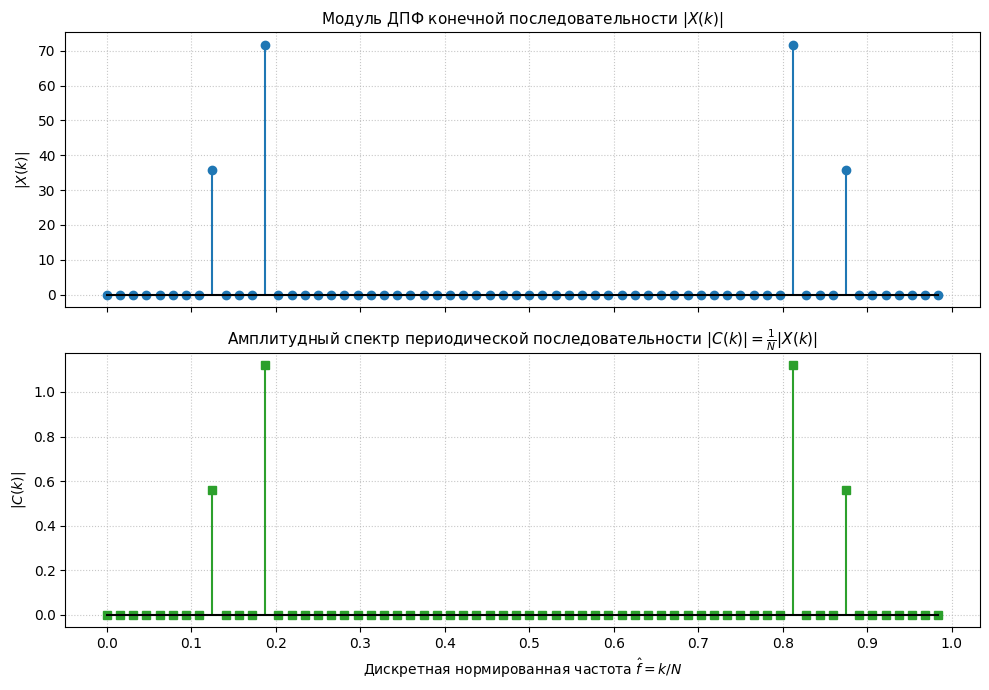

Пики модуля ДПФ конечной последовательности |X(k)|: 35.84 (k=8) и 71.68 (k=12)
Пики спектра периодической последовательности |C(k)|: 0.56 (k=8) и 1.12 (k=12)
Отношение амплитуд |X(k)| / |C(k)|: 64.0


In [11]:
# Модуль ДПФ конечной последовательности и спектр периодической последовательности
mag_X_finite = np.abs(X_dft)
mag_C_periodic = amplitude_spectrum

# Построение графиков stem в единой шкале нормированных частот
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Модуль ДПФ конечной последовательности
axes[0].stem(norm_freq, mag_X_finite, basefmt="k-", linefmt="#1f77b4", markerfmt="o")
axes[0].set_title(r"Модуль ДПФ конечной последовательности $|X(k)|$", fontsize=11)
axes[0].set_ylabel(r"$|X(k)|$", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.7)

# Амплитудный спектр периодической последовательности
axes[1].stem(norm_freq, mag_C_periodic, basefmt="k-", linefmt="#2ca02c", markerfmt="s")
axes[1].set_title(r"Амплитудный спектр периодической последовательности $|C(k)| = \frac{1}{N}|X(k)|$", fontsize=11)
axes[1].set_xlabel(r"Дискретная нормированная частота $\hat{f} = k/N$", fontsize=10)
axes[1].set_ylabel(r"$|C(k)|$", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.7)
axes[1].set_xticks(np.arange(0, 1.01, 0.1))

plt.tight_layout()
plt.show()

print(f"Пики модуля ДПФ конечной последовательности |X(k)|: {mag_X_finite[8]:.2f} (k=8) и {mag_X_finite[12]:.2f} (k=12)")
print(f"Пики спектра периодической последовательности |C(k)|: {mag_C_periodic[8]:.2f} (k=8) и {mag_C_periodic[12]:.2f} (k=12)")
print(f"Отношение амплитуд |X(k)| / |C(k)|: {mag_X_finite[8] / mag_C_periodic[8]:.1f}")


##### Анализ связи ДПФ конечной и периодической последовательностей
Модуль ДПФ конечной последовательности $|X(k)|$ и амплитудный спектр периодической последовательности $|C(k)|$ имеют тождественную форму спектральных линий, однако их численные амплитуды различаются ровно в $N = 64$ раза:
$$|X(k)| = N \cdot |C(k)|.$$
- Пики модуля ДПФ конечной последовательности равны:
  $$|X(8)| = |X(56)| = \frac{N A_1}{2} = \frac{64 \cdot 1.12}{2} = 35.84,$$
  $$|X(12)| = |X(52)| = \frac{N A_2}{2} = \frac{64 \cdot 2.24}{2} = 71.68.$$
- Пики амплитудного спектра периодической последовательности соответствуют половинам амплитуд комплексных гармоник ряда Фурье:
  $$|C(8)| = |C(56)| = \frac{A_1}{2} = 0.56, \qquad |C(12)| = |C(52)| = \frac{A_2}{2} = 1.12.$$
- Спектр конечной последовательности можно представить как непрерывную функцию частоты, полученную преобразованием Фурье конечного блока отсчётов. ДПФ представляет собой выборку этой функции в дискретных частотных точках $\hat{\omega}_k=2\pi k/N$. При периодическом продолжении блока значения ДПФ, поделённые на $N$, становятся коэффициентами дискретного ряда Фурье периодической последовательности.


#### Пункт 5. Восстановление аналогового сигнала по отсчётам ДПФ
Восстанавливается периодический аналоговый сигнал $x(t)$ по отсчетам ДПФ с помощью тригонометрического интерполяционного ряда на интервале $t \in [0, (N-1)T]$ с мелким шагом $\Delta t = 0.25T$:
$$x(t) = \frac{1}{N} \sum_{k = -N/2}^{N/2-1} X_{\mathrm{a}}(k) \exp\left(j\frac{2\pi}{NT} kt\right),$$
$$X_{\mathrm{a}}(k) = \begin{cases} X(N+k), & -N/2 \le k \le -1, \\ X(k), & 0 \le k \le N/2 - 1. \end{cases}$$
Строятся все 3 группы графиков, предписанные заданием.


Максимальная погрешность восстановления непрерывного сигнала: 3.543e-14


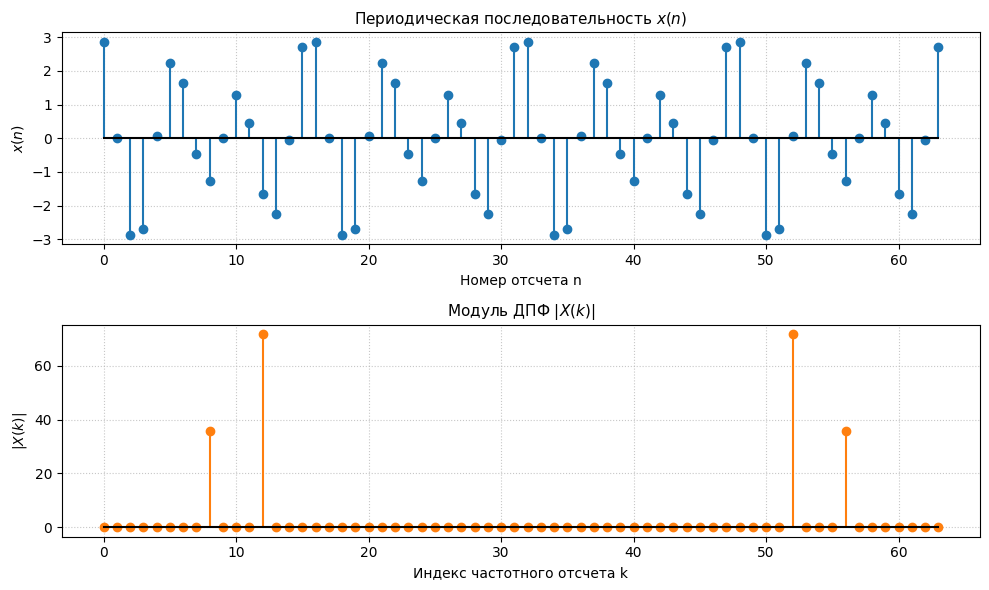

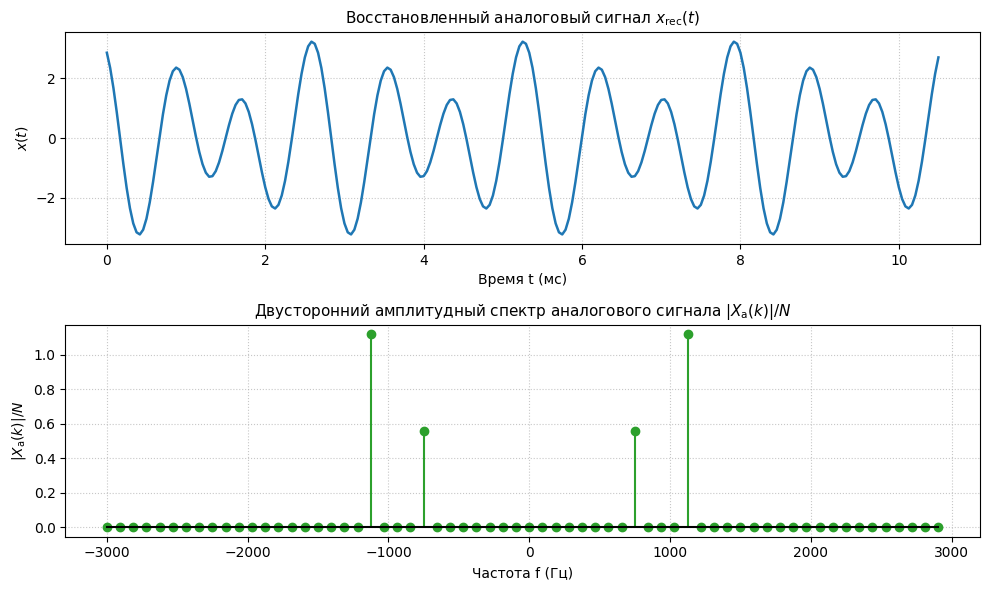

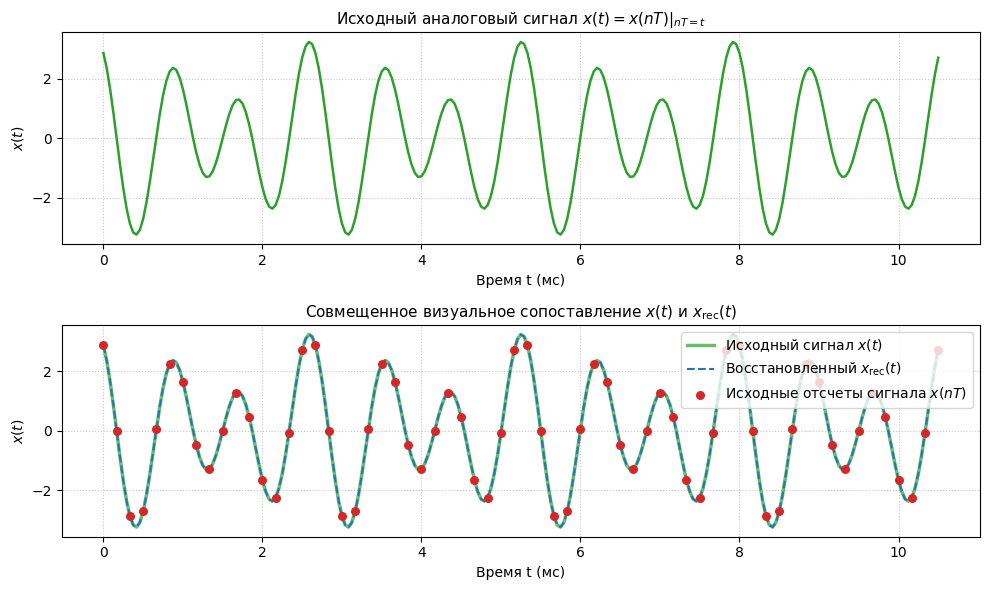

In [ ]:
# Формирование центрированного спектра X_a(k) для k in [-N/2, N/2 - 1]
k_signed = np.arange(-N_dft // 2, N_dft // 2)
# mod(k, N) отображает k in [-N/2, -1] в [N/2, N-1], а k in [0, N/2-1] в [0, N/2-1]
X_a = X_dft[np.mod(k_signed, N_dft)]

# Временная сетка с шагом Delta t = 0.25*T
t_dense = np.arange(0, (N_dft - 1) * T_sampling + 0.25 * T_sampling, 0.25 * T_sampling)

# Вычисление интерполяционной суммы
fourier_matrix = np.exp(1j * 2.0 * np.pi * np.outer(t_dense, k_signed) / (N_dft * T_sampling))
x_reconstructed_analog = np.real((fourier_matrix @ X_a) / float(N_dft))

# Исходный непрерывный сигнал
x_true_analog = A1 * np.cos(2.0 * np.pi * f1 * t_dense + np.pi / 4.0) + A2 * np.cos(2.0 * np.pi * f2 * t_dense + np.pi / 8.0)
max_recon_error = np.max(np.abs(x_reconstructed_analog - x_true_analog))
print(f"Максимальная погрешность восстановления непрерывного сигнала: {max_recon_error:.3e}")

# --- Группа 1: Периодическая последовательность и модуль ДПФ ---
fig1, ax1 = plt.subplots(2, 1, figsize=(10, 6))
ax1[0].stem(n_seq, x_periodic, basefmt="k-", linefmt="#1f77b4", markerfmt="o")
ax1[0].set_title(r"Периодическая последовательность $x(n)$", fontsize=11)
ax1[0].set_xlabel("Номер отсчета n", fontsize=10)
ax1[0].set_ylabel(r"$x(n)$", fontsize=10)
ax1[0].grid(True, linestyle=":", alpha=0.7)

ax1[1].stem(k_indices, mag_X_finite, basefmt="k-", linefmt="#ff7f0e", markerfmt="o")
ax1[1].set_title(r"Модуль ДПФ $|X(k)|$", fontsize=11)
ax1[1].set_xlabel("Индекс частотного отсчета k", fontsize=10)
ax1[1].set_ylabel(r"$|X(k)|$", fontsize=10)
ax1[1].grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()

# --- Группа 2: Восстановленный аналоговый сигнал и его двусторонний амплитудный спектр ---
fig2, ax2 = plt.subplots(2, 1, figsize=(10, 6))
ax2[0].plot(t_dense * 1000.0, x_reconstructed_analog, color="#1f77b4", linewidth=1.8)
ax2[0].set_title(r"Восстановленный аналоговый сигнал $x_{\mathrm{rec}}(t)$", fontsize=11)
ax2[0].set_xlabel("Время t (мс)", fontsize=10)
ax2[0].set_ylabel(r"$x(t)$", fontsize=10)
ax2[0].grid(True, linestyle=":", alpha=0.7)

freq_signed_hz = k_signed * (fd_signal / float(N_dft))
ax2[1].stem(freq_signed_hz, np.abs(X_a) / float(N_dft), basefmt="k-", linefmt="#2ca02c", markerfmt="o")
ax2[1].set_title(r"Двусторонний амплитудный спектр аналогового сигнала $|X_{\mathrm{a}}(k)|/N$", fontsize=11)
ax2[1].set_xlabel("Частота f (Гц)", fontsize=10)
ax2[1].set_ylabel(r"$|X_{\mathrm{a}}(k)|/N$", fontsize=10)
ax2[1].grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()

# --- Группа 3: Исходный аналоговый сигнал и совмещенное визуальное сопоставление ---
fig3, ax3 = plt.subplots(2, 1, figsize=(10, 6))
ax3[0].plot(t_dense * 1000.0, x_true_analog, color="#2ca02c", linewidth=1.8)
ax3[0].set_title(r"Исходный аналоговый сигнал $x(t) = x(nT)\vert_{nT = t}$", fontsize=11)
ax3[0].set_xlabel("Время t (мс)", fontsize=10)
ax3[0].set_ylabel(r"$x(t)$", fontsize=10)
ax3[0].grid(True, linestyle=":", alpha=0.7)

ax3[1].plot(t_dense * 1000.0, x_true_analog, color="#2ca02c", linewidth=2.5, alpha=0.7, label=r"Исходный сигнал $x(t)$")
ax3[1].plot(t_dense * 1000.0, x_reconstructed_analog, color="#1f77b4", linestyle="--", linewidth=1.5, label=r"Восстановленный $x_{\mathrm{rec}}(t)$")
ax3[1].scatter(t_seq * 1000.0, x_periodic, color="#d62728", s=30, zorder=5, label=r"Исходные отсчеты сигнала $x(nT)$")
ax3[1].set_title(r"Совмещенное визуальное сопоставление $x(t)$ и $x_{\mathrm{rec}}(t)$", fontsize=11)
ax3[1].set_xlabel("Время t (мс)", fontsize=10)
ax3[1].set_ylabel(r"$x(t)$", fontsize=10)
ax3[1].grid(True, linestyle=":", alpha=0.7)
ax3[1].legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


#### Пункт 6. Анализ результатов восстановления аналогового сигнала
1. **Связь модуля ДПФ последовательности со спектром аналогового сигнала:**
   отсчеты центрированного ДПФ $X_{\mathrm{a}}(k)$ напрямую соответствуют дискретным гармоникам непрерывного ряда Фурье периодического аналогового сигнала $x(t)$. Модуль коэффициента каждой отдельной спектральной линии двустороннего спектра равен $|X_{\mathrm{a}}(k)|/N$, то есть половине физической амплитуды гармоники ($A_1/2 = 0.56$ на $k = \pm 8$ и $A_2/2 = 1.12$ на $k = \pm 12$).
   

2. **Результат визуального и численного сравнения:**
   на совмещенном графике восстановленный непрерывный сигнал $x_{\mathrm{rec}}(t)$ идеально совпадает с эталонным аналитическим сигналом $x(t)$, в точности проходя через исходные отсчеты $x(nT)$. Максимальное абсолютное численное расхождение между ними составляет порядка $3.5 \cdot 10^{-14}$, что является пределом точности машинной арифметики с плавающей точкой (IEEE 754 float64).
   Идеальное восстановление обусловлено двумя фундаментальными факторами:
   - Частота дискретизации $f_{\mathrm{d}} = 6000\text{ Гц}$ удовлетворяет теореме Котельникова с запасом: $f_{\mathrm{d}} > 2 f_{\max} = 2 \cdot 1125 = 2250\text{ Гц}$.
   - Частоты гармоник $f_1$ и $f_2$ кратны частотному разрешению ДПФ ($\Delta f = 93.75\text{ Гц}$), что исключило эффект растекания спектра.


#### Пункт 7. Проверка равенства Парсеваля
Выполняется численная проверка сохранения энергии сигнала во временной и частотной областях в соответствии с теоремой Парсеваля.


In [13]:
# Численный расчет энергии сигнала
energy_time = np.sum(np.abs(x_periodic) ** 2)
energy_freq = np.sum(np.abs(X_dft) ** 2) / float(N_dft)
parseval_error = np.abs(energy_time - energy_freq)

print(f"Энергия во временной области:            {energy_time:.12f}")
print(f"Энергия в частотной области (1/N * sum): {energy_freq:.12f}")
print(f"Абсолютная невязка энергии:              {parseval_error:.3e}")
print(f"Равенство Парсеваля выполняется: {np.isclose(energy_time, energy_freq, atol=1e-12)}")


Энергия во временной области:            200.704000000000
Энергия в частотной области (1/N * sum): 200.704000000000
Абсолютная невязка энергии:              8.527e-14
Равенство Парсеваля выполняется: True


##### Анализ равенства Парсеваля
Энергия последовательности во временной области составляет $\sum_{n=0}^{63} |x(n)|^2 = 200.704000$. Энергия спектральных отсчётов с нормировочным множителем $1/N$ совпадает с энергией во временной области с точностью до погрешности вычислений с плавающей точкой. Абсолютное расхождение составляет $\approx 8.5 \cdot 10^{-14}$, что соответствует ошибке округления операций с плавающей точкой.
Равенство Парсеваля показывает, что энергия сигнала, рассчитанная во временной и частотной областях, одинакова с учётом нормировки ДПФ.


## Выводы

В ходе практической работы исследованы линейные дискретные системы и дискретное преобразование Фурье.

1. **Линейные дискретные системы.** Рассчитана импульсная характеристика рекурсивного звена второго порядка, получено её аналитическое выражение. Вычислены нули и полюсы передаточной функции, подтверждена устойчивость системы. Построены АЧХ и ФЧХ, выявлены области подавления и усиления частотных составляющих.

2. **Дискретное преобразование Фурье.** Выполнены прямое и обратное ДПФ, исследованы амплитудный и фазовый спектры. Восстановлен аналоговый сигнал с максимальной погрешностью порядка $3.5\cdot10^{-14}$. Проверено равенство Парсеваля: энергия сигнала составляет $200.704$ в обеих областях с учётом вычислительной погрешности.

3. **Возникшие сложности.** При сравнении свёртки с решением разностного уравнения обнаружилось расхождение, обусловленное усечением бесконечной импульсной характеристики. При анализе ФЧХ потребовалось различать переброс главного значения фазы и действительное изменение фазы. Обе особенности были учтены при интерпретации результатов.
